In [1]:
from riemann_problem import RiemannProblem
from calculation import Calculation

task = RiemannProblem(mesh = "mesh.csv", 
                    states = {"left": {
                            "density": 1.0,
                            "velocity": 0.0,
                            "pressure": 1.0
                          },
                           "right": {
                            "density": 0.125,
                            "velocity": 0.0,
                            "pressure": 0.1
                          }
                        },
                    time = {"t_end": 0.1, "N": 100},
                    modules = {
                     "solver": "exact",
                     "eos": "ideal",
                     "eos_params": {"gamma": 1.4}
                 })
calc = Calculation("../sandbox/python_test", task)
calc.run()

Заглушка завершена: "/home/sq/workspace/gas_dynamics/sandbox/python_test"
Точек x: 1001, временных слоёв: 100


In [2]:
from graph import plot, plot_time_layer, riemann_xt, riemann_pu

(<Figure size 1020x540 with 1 Axes>,
 <Axes: title={'center': 't = 0.1'}, xlabel='$x$', ylabel='density'>)

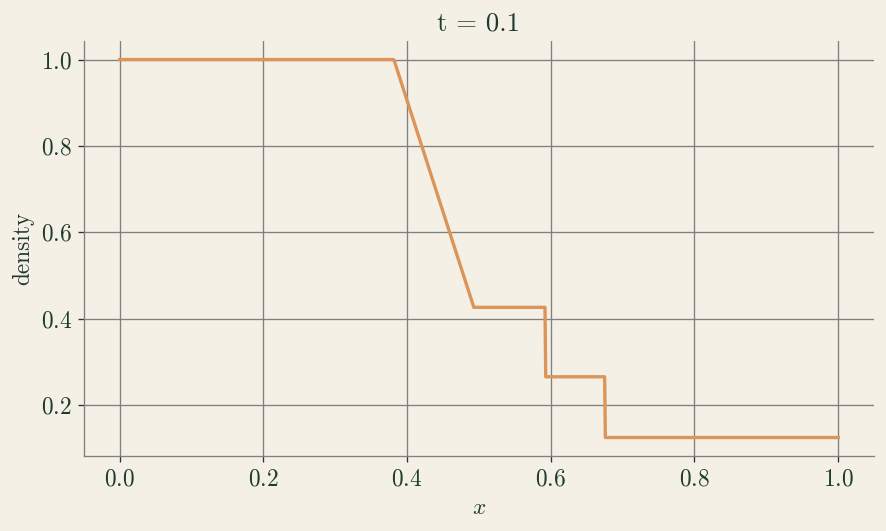

In [3]:
plot_time_layer(calc, "density")

(<Figure size 1020x540 with 1 Axes>,
 <Axes: title={'center': 't = 0.1'}, xlabel='$x$', ylabel='density'>)

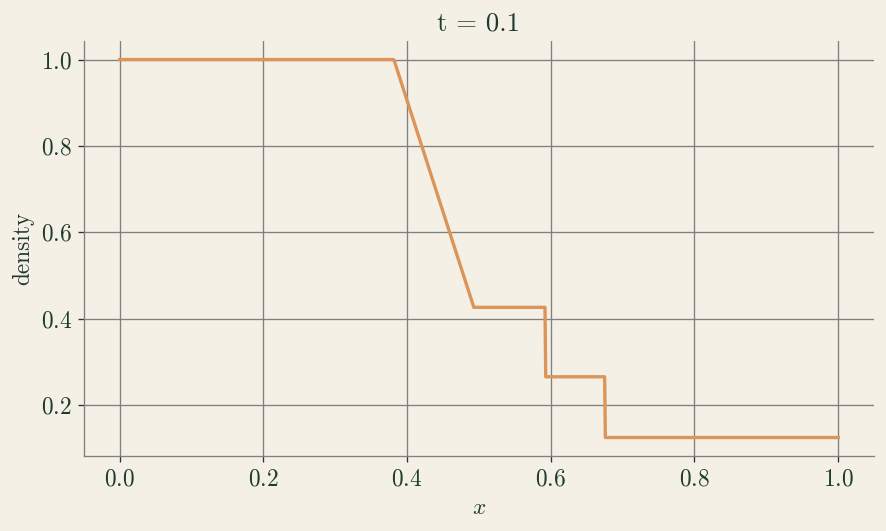

In [4]:
plot_time_layer(calc, "density")

(<Figure size 1020x540 with 1 Axes>,
 <Axes: title={'center': 't = 0.1'}, xlabel='$x$', ylabel='pressure'>)

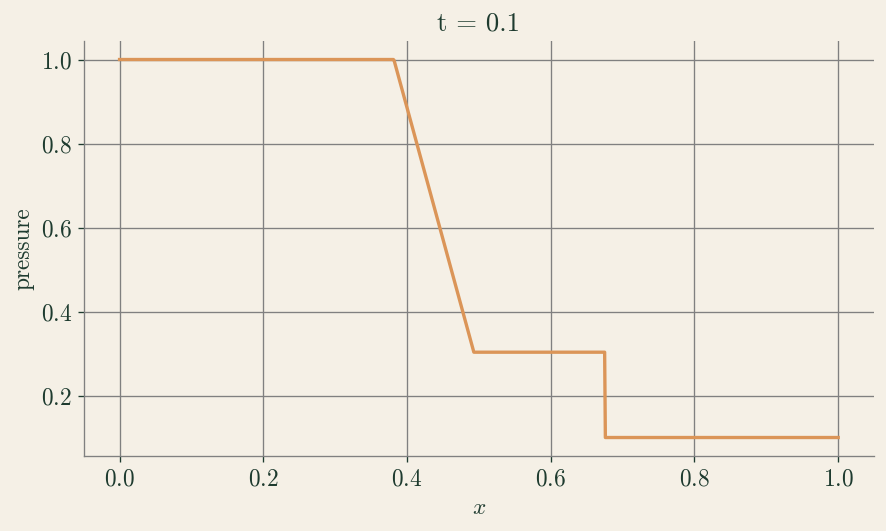

In [5]:
plot_time_layer(calc, "pressure")

(<Figure size 1020x540 with 1 Axes>,
 <Axes: title={'center': 't = 0.0101'}, xlabel='$x$', ylabel='velocity'>)

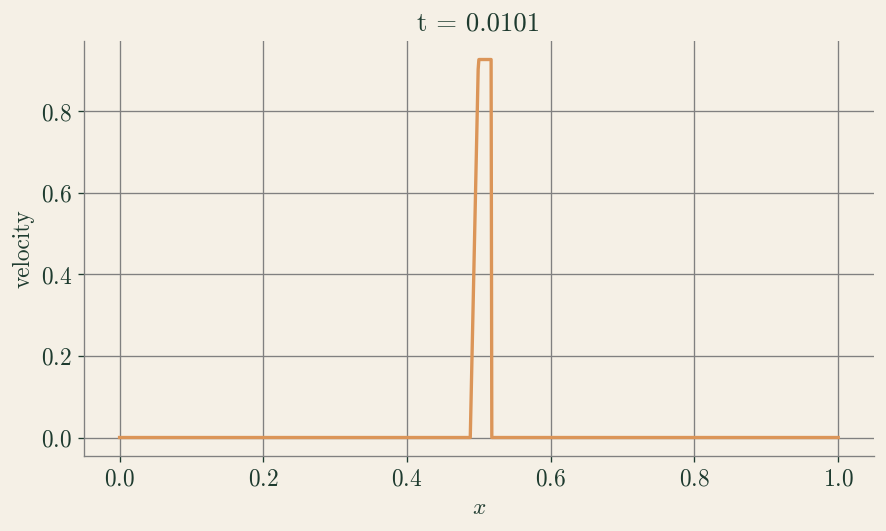

In [6]:
plot_time_layer(calc, "velocity", layer=10)

(<Figure size 1020x540 with 1 Axes>, <Axes: xlabel='t'>)

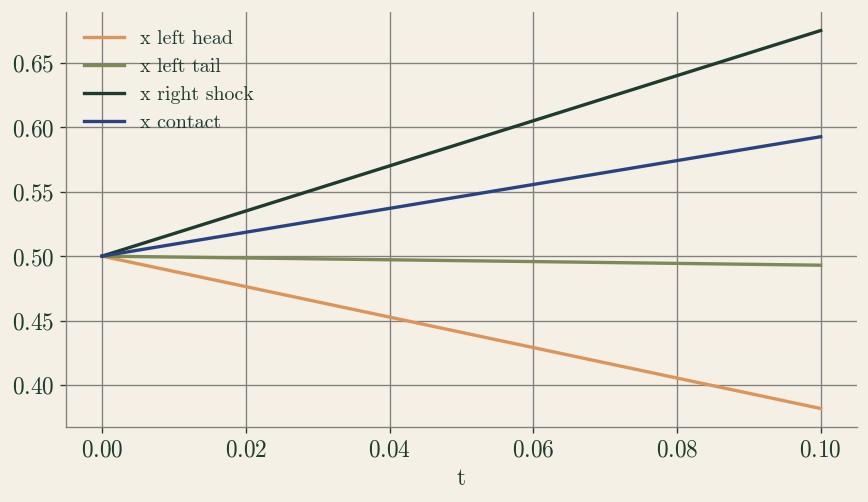

In [7]:
names = []
#Определяем какие типы волн записаны
for side in ("left", "right"):
    if f"x_{side}_shock" in calc.quantities:
        names.append(f"x_{side}_shock")
    else:
        names.extend(
            name for name in (f"x_{side}_head", f"x_{side}_tail")
            if name in calc.quantities
        )

# Контактный разрыв
if "x_contact" in calc.quantities:
    names.append("x_contact")

# Строим только найденные величины
plot(calc, *names)


(<Figure size 1020x540 with 1 Axes>, <Axes: xlabel='x', ylabel='t'>)

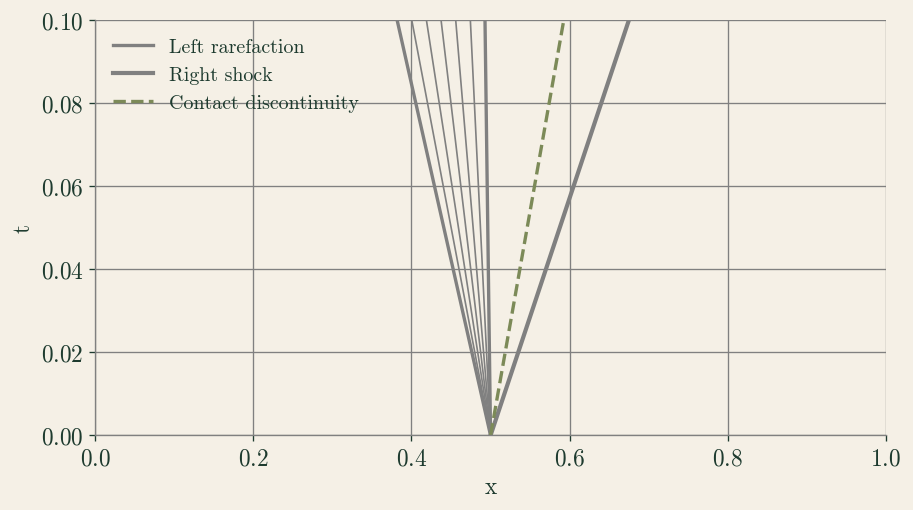

In [8]:
riemann_xt(calc)

(<Figure size 1020x540 with 1 Axes>, <Axes: xlabel='u', ylabel='p'>)

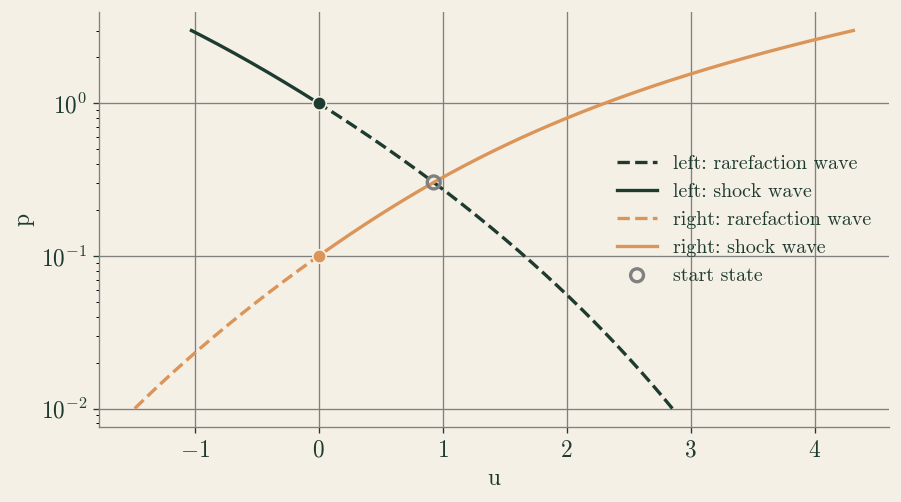

In [9]:
riemann_pu(calc)

In [10]:
from calculation import Calculation
calc1 = Calculation.open("../sandbox/python_test")